In [1]:
import json
import os

from IPython.display import Image, Markdown, display


def load(name):
    with open(os.path.join("parts", name + ".json")) as file:
        return json.load(file)


def cell(value, form):
    if value is None:
        return "—"
    if callable(form):
        return form(value)
    return format(value, form) if form else str(value)


def table(rows, columns):
    """columns: (header, a key or a function of the row, a format spec or a function)"""
    def value(row, pick):
        return pick(row) if callable(pick) else row.get(pick)
    lines = ["| " + " | ".join(header for header, _, _ in columns) + " |",
             "|" + "---|" * len(columns)]
    for row in rows:
        lines.append("| " + " | ".join(cell(value(row, pick), form) for _, pick, form in columns) + " |")
    display(Markdown("\n".join(lines)))


def figure(path):
    display(Image(filename=path, width=720))

# EP4 measurement: NVIDIA GeForce RTX 5070 Laptop GPU

2026-11-22 20:25:24 · host `Welton` · engine code `72b86b63cbf7` ·
`python main.py measure --yes`

**What this is.** The raw results of one `measure` run: every engine run it made is a file in `points/`, every
analysis a file in `parts/`, every figure in `figures/`. The tables below are read from those files when the notebook
runs, so re-running it rebuilds them; the sentences that interpret them were written from the same numbers.

**The star measured:** 1024² pixels, 300 frames, 4 observers, 3 spots: 5.03 GB of image per run. Every run in this report traces it, records it and saves it: the
serial part of each run (zeroing, copying back and saving the image) is that of a real high-resolution picture.

## The machine

| | |
|---|---|
| GPU | NVIDIA GeForce RTX 5070 Laptop GPU, compute capability 12.0, 36 SMs |
| per SM | 65536 registers, 1536 threads, 24 blocks |
| CPU (correctness only) | —: the sequential engine the GPU's images are checked against; its speed is not compared |
| software | Build cuda_13.3.r13.3/compiler.38244171_0; driver 621.14 |

## What makes a valid run

A run measures speed only if the GPU is busy long enough and evenly enough. Two rules, the larger wins: (1) at least 1 s of photons, so that the launch and the clock's ramp-up don't dominate; (2) at least 32 chunks per resident thread, so that every SM gets a fair share and the slowest one doesn't decide the time (at 10⁷ photons on the laptop: 9 766 chunks for 27 648 threads, and pass times varied 0.6–1.6×; research/pass_order.py).

| binary | SMs | minimum N | by time (1 s) | by work (32 chunks per thread) | resident threads | N used here |
|---|---|---|---|---|---|---|
| gpu64 | 36 | 9.06e+08 | 6.41e+08 | 9.06e+08 | 27648 | 4.00e+09 |
| gpu64 | 1 | 2.52e+07 | 1.78e+07 | 2.52e+07 | 768 | 4.00e+09 |
| gpu32 | 36 | 1.10e+10 | 1.10e+10 | 1.06e+09 | 32256 | 5.00e+10 |
| gpu32 | 1 | 3.05e+08 | 3.05e+08 | 2.94e+07 | 896 | 5.00e+10 |

On one SM the work rule asks for far less (one SM's threads), and the same N simply runs longer. **Every timed run is
above the minimum**: `measure` refuses to run otherwise. The only runs at a smaller N are the validation checks
against the sequential CPU (N = 10⁸): they compare images, not times, and the CPU side alone would need about an hour at 10¹⁰.

## 1. Is the physics right? (validation)

**Question.** Does the GPU compute the same star as the sequential CPU engine, both photon by photon and in the
statistics of the image?

**Method.**
- *GPU vs CPU, the same photons:* the same seed, so the same random numbers; the images compared bit for bit.
- *GPU vs CPU, independent photons:* the same seed, so the same star and spots, but different chunks (each chunk is
  its own random stream): two independent Monte Carlo images of the same star. The χ² of their difference (frames
  summed), per degree of freedom: the same physics gives χ²/dof ≈ 1 (|σ| < 3 passes). Not different seeds: the seed
  also places the spots, so another seed is another star.
- *FP32 vs FP64:* the same seed, so the same photons; the fraction of photons that land in another pixel in FP32,
  next to the Poisson noise per lit pixel.

In [2]:
checks = load("validation")["checks"]
table(checks, [("check", lambda c: f"{c['name']} ({c['processor']}{c['precision']})", None),
               ("N", lambda c: c["data"].get("photons"), ".1e"),
               ("passed", "passed", lambda v: {True: "yes", False: "NO"}.get(v, "—")),
               ("result", "headline", None)])

| check | N | passed | result |
|---|---|---|---|
| independent (gpu64) | 1.0e+08 | yes | χ²/dof = 0.9904: the same physics within noise |
| precision (gpu64) | 4.0e+09 | — | FP32 moves 7.17e-04 of the photons (noise 1.41e-01); 16.17× the speed of FP64 |
| gpu (gpu64) | 1.0e+08 | yes | the GPU vs the sequential CPU: the images are identical, bit for bit |
| gpu (gpu32) | 1.0e+08 | — | the GPU vs the sequential CPU: 2484 pixels differ (2.98e-04 of the photons moved) |

**What it means.**
- GPU vs the sequential CPU with independent photons: χ²/dof = 0.9904 over
  51899 blocks of 8×8 pixels
  (summed so that each block holds enough photons for the test), -1.55 σ from 1:
  the same physics within the noise.
- FP32 moves 7.17e-04 of the photons to another pixel; the noise per lit pixel is
  1.41e-01, so the FP32 error is 196× smaller than the noise. FP32 is
  16.2× faster than FP64 on this GPU.
- GPU vs CPU, FP64: identical, bit for bit.
  FP32: 2.98e-04 of the photons moved (the GPU's `sinf`,
  `cosf` and fused multiply-adds round differently from the CPU's).

**Caveats.** The χ² test is statistical: about 1 run in 370 fails it by chance. The bit-for-bit results hold for this
build and this seed; they don't depend on N.

## 2. How fast is the GPU, one SM and all of them? (speed)

**Question.** Photons per second on one SM and on all 36, in FP64 and FP32. The unit of comparison is the SM:
the GPU against itself, not against another processor.

**Method.** The measured star (its image is in the opening, under *The machine*), the same N on one SM and on all of
them, repeated. The speed is N over the photon phase alone (the kernel): setup and save are left out. The one-SM run
is also the first point of the strong sweep (section 5).

| precision | SMs | N | photons/s (median) | min – max | SM clock (MHz) | power (W) | power cap | repeats |
|---|---|---|---|---|---|---|---|---|
| FP64 | 1 | 4.0e+09 | 1.84e+07 | 1.83e+07 – 1.87e+07 | 2887 | 30 | 0% | 3 |
| FP64 | 36 | 4.0e+09 | 6.69e+08 | 6.27e+08 – 6.7e+08 | 2610 | 36 | 0% | 3 |
| FP32 | 1 | 5.0e+10 | 3.15e+08 | 3.02e+08 – 3.2e+08 | 2895 | 34 | 0% | 3 |
| FP32 | 36 | 5.0e+10 | 1.11e+10 | 1.05e+10 – 1.11e+10 | 2017 | 44 | 37% | 3 |

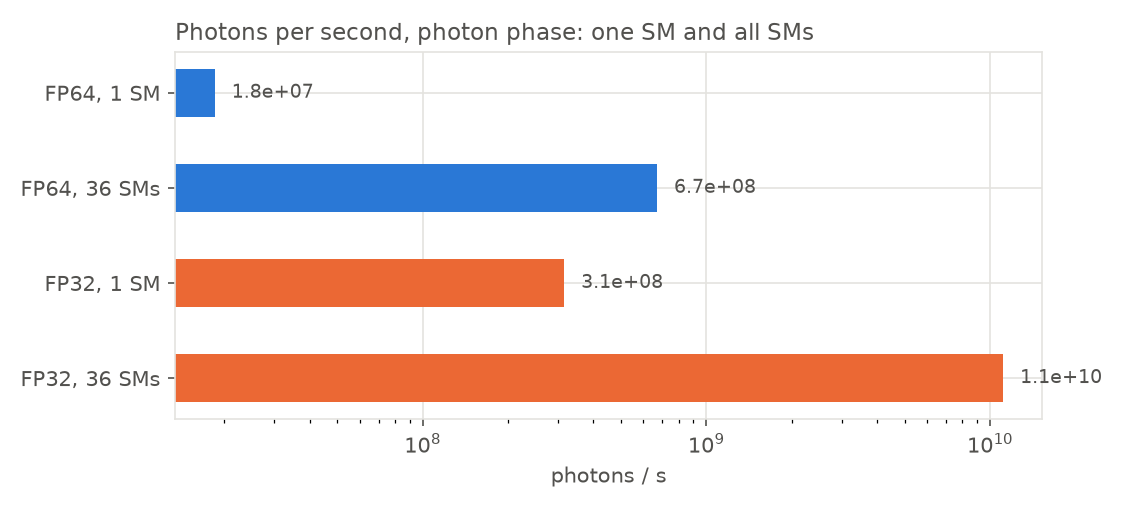

In [3]:
speed = load("speed")
table(speed["rows"], [("precision", lambda r: f"FP{r['precision']}", None), ("SMs", "sms", None), ("N", "photons", ".1e"),
                      ("photons/s (median)", lambda r: r["photons_per_second"]["median"], ".3g"),
                      ("min – max", lambda r: f"{r['photons_per_second']['min']:.3g} – {r['photons_per_second']['max']:.3g}", None),
                      ("SM clock (MHz)", "sm_clock_mhz", ".0f"), ("power (W)", "power_w", ".0f"),
                      ("power cap", "power_cap_share", ".0%"), ("repeats", lambda r: r["photons_per_second"]["repeats"], None)])
figure("figures/speed.png")

**What it means.**
- One SM: 1.84e+07 photons/s in FP64,
  3.15e+08 in FP32.
- All 36 SMs: 6.69e+08 in FP64 (36.3× one SM, so each
  SM keeps 101% of its one-SM speed), 1.11e+10 in FP32
  (35.3×, 98%).
- FP32 over FP64: 17.1× on one SM, 16.6× on all
  of them. This GPU has few FP64 units per SM, so an FP64 photon costs far more than an FP32 one.

**Caveats.** With every SM busy in FP32 the GPU reaches its power limit and lowers its clock, so the speed per SM falls
(the SM clock column); section 5 shows the same scaling in cycles, without the clock.

## 3. What the kernel is made of (kernel)

**Question.** What does the compiler make of `trace_photons`, and which changes to it matter?

**Method.** The resources come from the compiler (`ptxas -v`) and the CUDA runtime (`cudaFuncGetAttributes`, the
occupancy API). The instruction mix counts the instructions in the kernel's machine code (SASS) by the unit that runs
them. Each variant is a rebuild with one change, run at the same N as the baseline:
- `scene_in_global`: the scene in global memory instead of constant memory;
- `no_fma`: no fused multiply-adds (`--fmad=false`);
- `sections`: timers around each piece of the photon (cycles per section), to see where the time goes.

In [4]:
kernel = load("kernel")
print("Resources")
table([dict(r, precision=p) for p, r in kernel["resources"].items()],
      [("precision", "precision", None), ("registers", "registers", None), ("spills (B)", "spill_bytes", None),
       ("constant (B)", "constant_bytes", None), ("threads/block", "threads_per_block", None),
       ("blocks/SM", "blocks_per_sm", None), ("occupancy", "occupancy", ".2f")])
mix = kernel["instruction_mix"]
units = sorted({unit for counts in mix.values() for unit in counts})
print("Instruction mix (static: instructions in the code, not how often they run)")
table([dict({"unit": unit}, **{name: counts.get(unit, 0) for name, counts in mix.items()}) for unit in units],
      [("unit", "unit", None)] + [(name, name, None) for name in mix])
for precision, rows in kernel["variants"].items():
    print(f"Variants, {precision}")
    table(rows, [("variant", "variant", None), ("registers", "registers", None), ("spills (B)", "spill_bytes", None),
                 ("kernel (s)", lambda r: r["kernel_time"]["median"], ".3f"),
                 ("time vs baseline", "time_vs_baseline", ".3f"), ("cycles vs baseline", "cycles_vs_baseline", ".3f"),
                 ("same image", "image_equals_baseline", lambda v: "yes" if v else "no")])
for precision, sections in kernel["sections"].items():
    print(f"Where the time goes, {precision} (cycles per section, the sections build)")
    table(sorted(sections, key=lambda s: -s["share"]), [("section", "name", None), ("share", "share", ".1%")])

Resources


| precision | registers | spills (B) | constant (B) | threads/block | blocks/SM | occupancy |
|---|---|---|---|---|---|---|
| fp64 | 80 | 0 | 18048 | 768 | 1 | 0.50 |
| fp32 | 67 | 0 | 17256 | 896 | 1 | 0.58 |

Instruction mix (static: instructions in the code, not how often they run)


| unit | star_gpu64 | star_gpu32 |
|---|---|---|
| FP32 cores | 73 | 247 |
| FP64 units | 278 | 4 |
| atomics (L2) | 2 | 2 |
| constant loads | 46 | 49 |
| control flow | 1261 | 296 |
| conversions | 25 | 25 |
| global memory | 14 | 5 |
| integer units | 660 | 624 |
| local memory (stack, spills) | 5 | 20 |
| moves, special registers | 250 | 154 |
| other | 45 | 48 |
| special function unit (MUFU) | 13 | 12 |
| uniform datapath | 66 | 28 |
| warp-wide | 6 | 6 |

Variants, fp64


| variant | registers | spills (B) | kernel (s) | time vs baseline | cycles vs baseline | same image |
|---|---|---|---|---|---|---|
| baseline | 80 | 0 | 5.967 | 1.000 | 1.000 | yes |
| scene_in_global | 88 | 0 | 6.367 | 1.067 | 0.996 | yes |
| no_fma | 80 | 0 | 6.409 | 1.074 | 1.075 | yes |
| sections | 112 | 0 | 5.911 | 0.991 | 0.991 | yes |

... (2 outputs left out)

Where the time goes, fp64 (cycles per section, the sections build)


| section | share |
|---|---|
| direction | 34.6% |
| bin | 22.3% |
| surface | 20.9% |
| record | 12.8% |
| spots | 8.6% |
| pixel | 0.7% |
| chunk | 0.0% |

Where the time goes, fp32 (cycles per section, the sections build)


| section | share |
|---|---|
| direction | 41.4% |
| surface | 28.1% |
| record | 12.3% |
| spots | 9.3% |
| bin | 8.5% |
| pixel | 0.5% |
| chunk | 0.0% |

**What it means.**
- Registers: 80 (FP64) and 67 (FP32),
  spills 0 / 0 bytes; the launch
  gives occupancy 0.50 / 0.58
  (section 4 explains why).
- Constant vs global memory for the scene: 1.07× the time in FP64, 1.01× in FP32.
- No FMA (separate multiply and add): 1.07× the time in FP64, 1.01× in FP32; the FP64 image is the same: fusing changed no photon's pixel here.
- The section timers cost 0.99× (FP64) and 1.50× (FP32): measuring changes what is measured. The largest section is *direction* (35% of the cycles, FP64) and *direction* (41%, FP32).

**Caveats.** The mix is static: a `NOP` or an FP64 instruction in a branch that never runs is counted like any other
(`research/nop_runs.py`, `research/fp64_in_fp32_kernel.py`). Times are medians of the repeats; their spread is in
`parts/kernel.json`.

## 4. Registers and occupancy (occupancy)

**Question.** The registers each thread needs limit how many warps an SM can hold (the occupancy). Would more warps
per SM make the kernel faster?

**The arithmetic.** An SM has 65536 registers and holds at most
1536 threads (48 warps of
32). Registers are given per warp, in steps of 8 per thread: a warp of threads needing *r* registers
takes ⌈r/8⌉·8·32. So the warps that fit are 65536 / (⌈r/8⌉·8·32), at most
48, and the occupancy is that over
48.

**Method.** Rebuild the kernel with `-maxrregcount` caps; the compiler then keeps fewer values in registers and spills
the rest to local memory. Each cap runs at the same N, the caps interleaved (forward, then backward) so that a clock
drifting during the sweep hits all of them alike. The speed is compared in **cycles of the slowest SM**, which don't
depend on the clock.

This GPU, uncapped


| precision | registers | per warp | warps the registers allow | of | threads per SM | occupancy at most |
|---|---|---|---|---|---|---|
| fp64 | 80 | 2560 | 25 | 48 | 800 | 0.52 |
| fp32 | 67 | 2304 | 28 | 48 | 896 | 0.58 |

The caps, fp64


| cap | registers | warps allowed | occupancy | spills (B) | cycles vs uncapped | time vs uncapped | MHz | power cap | same image |
|---|---|---|---|---|---|---|---|---|---|
| none | 80 | 25 | 0.50 | 0 | 1.000 | 1.000 | 2610 | 0% | yes |
| 72 | 72 | 28 | 0.58 | 0 | 0.999 | 1.071 | 2017 | 0% | yes |
| 64 | 64 | 32 | 0.67 | 24 | 1.001 | 1.000 | 2407 | 0% | yes |
| 56 | 56 | 36 | 0.75 | 84 | 1.049 | 1.048 | 2880 | 0% | yes |
| 48 | 48 | 42 | 0.83 | 164 | 1.072 | 1.071 | 2880 | 0% | yes |
| 40 | 40 | 51 | 1.00 | 344 | 1.097 | 1.096 | 2880 | 0% | yes |
| 32 | 32 | 64 | 1.00 | 444 | 1.098 | 1.097 | 2880 | 0% | yes |

The caps, fp32


| cap | registers | warps allowed | occupancy | spills (B) | cycles vs uncapped | time vs uncapped | MHz | power cap | same image |
|---|---|---|---|---|---|---|---|---|---|
| none | 67 | 28 | 0.58 | 0 | 1.000 | 1.000 | 2017 | 37% | yes |
| 64 | 55 | 36 | 0.75 | 0 | 1.011 | 1.018 | 2058 | 40% | yes |
| 56 | 52 | 36 | 0.75 | 0 | 1.030 | 1.038 | 2017 | 38% | yes |
| 48 | 48 | 42 | 0.83 | 24 | 1.035 | 1.401 | 2017 | 12% | yes |
| 40 | 40 | 51 | 1.00 | 80 | 1.034 | 1.400 | 2017 | 44% | yes |
| 32 | 32 | 64 | 1.00 | 156 | 1.047 | 1.461 | 1545 | 46% | yes |

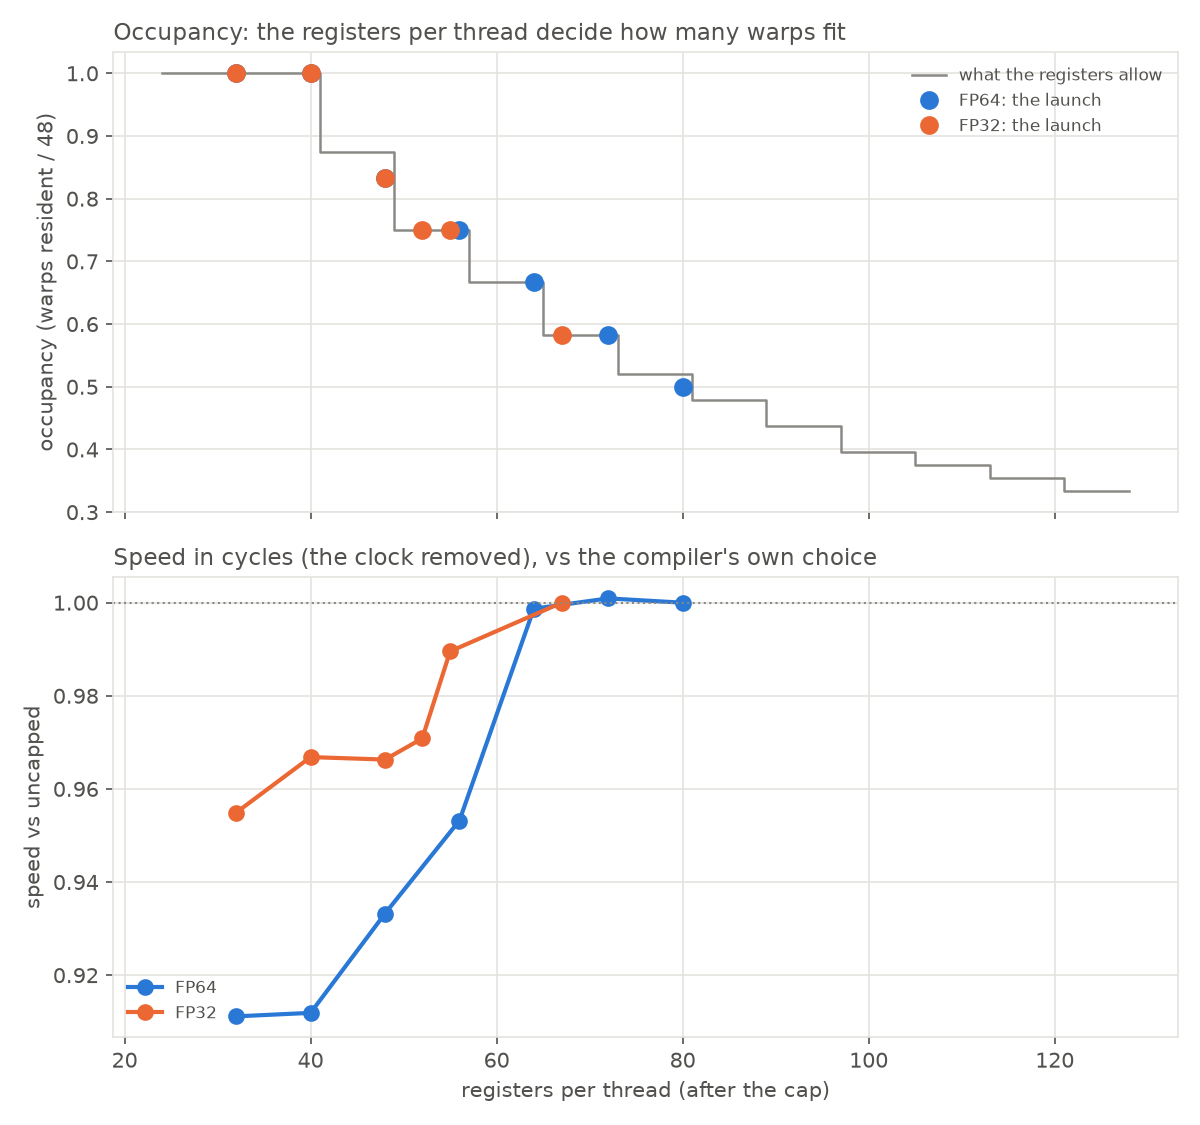

In [5]:
occupancy = load("occupancy")
print("This GPU, uncapped")
table([dict(r, precision=p) for p, r in occupancy["this_gpu"].items()],
      [("precision", "precision", None), ("registers", "registers", None), ("per warp", "registers_per_warp", None),
       ("warps the registers allow", "warps_allowed_by_registers", None), ("of", "max_warps", None),
       ("threads per SM", "threads_per_sm", None), ("occupancy at most", "occupancy_at_most", ".2f")])
for precision, rows in occupancy["rows"].items():
    print(f"The caps, {precision}")
    table(rows, [("cap", "cap", None), ("registers", "registers", None), ("warps allowed", "warps_allowed_by_registers", None),
                 ("occupancy", "occupancy", ".2f"), ("spills (B)", "spill_bytes", None),
                 ("cycles vs uncapped", "cycles_vs_baseline", ".3f"), ("time vs uncapped", "time_vs_baseline", ".3f"),
                 ("MHz", "sm_clock_mhz", ".0f"), ("power cap", "power_cap_share", ".0%"),
                 ("same image", "image_equals_baseline", lambda v: "yes" if v else "no")])
figure(occupancy["figure"])

**What it means.**
- FP64: the uncapped build uses 80 registers, so the registers allow occupancy 0.52; the launch gets 0.50, because blocks fit only whole. The fewest cycles: 72 registers (0.999× the uncapped cycles, occupancy 0.58). Full occupancy needs 40 registers: 1.097× the cycles, with 344 bytes spilled to local memory.
- FP32: the uncapped build uses 67 registers, so the registers allow occupancy 0.58. The fewest cycles: 67 registers (1.000× the uncapped cycles, occupancy 0.58). Full occupancy needs 40 registers: 1.034× the cycles, with 80 bytes spilled to local memory.

Other GPUs, from the compiler alone:
- A30 (NVIDIA's Ampere tuning guide) (sm_80): FP64 96 registers → occupancy at most 0.33; FP32 76 → 0.39 (compiled here, not run).

**Caveats.** "Power cap" is the share of `nvidia-smi` samples in which the driver held the clock down for power; the
cycles are immune to it, the times are not. On a GPU where the kernel waits on memory or on long latencies, more warps
can hide that wait; where it is bound by its arithmetic units, they can't.

## 5. Scaling: Amdahl and Gustafson (scaling)

**Question.** How does the time change with the number of SMs, for a fixed problem (strong scaling, Amdahl) and for a
problem that grows with the SMs (weak scaling, Gustafson)?

**Method.** The engine's `--sms n` keeps the work on n SMs. Strong: the same N on every n. Weak: N proportional to n.
Each point is repeated, interleaved; medians are used. Two times are kept: the **photon phase** (the kernel) and the
**whole run** (with the setup, zeroing and saving, which don't get faster with more SMs). Amdahl's law
T(n) = T(1)·(s + p/n) is fitted by least squares; Gustafson's scaled speedup is n − s′(n − 1).

### 5.1 Strong scaling

| SMs | photon phase (s) | whole run (s) | speedup, photons | speedup, whole run | speedup, cycles | SM clock (MHz) |
|---|---|---|---|---|---|---|
| 1 | 216.896 | 223.469 | 1.00 | 1.00 | 1.00 | 2887 |
| 2 | 112.120 | 118.416 | 1.93 | 1.89 | 2.01 | 2902 |
| 3 | 77.094 | 82.898 | 2.81 | 2.70 | 3.01 | 2902 |
| 4 | 53.471 | 59.431 | 4.06 | 3.76 | 4.02 | 2887 |
| 6 | 35.641 | 41.420 | 6.09 | 5.40 | 6.03 | 2887 |
| 9 | 23.780 | 30.402 | 9.12 | 7.35 | 9.04 | 2887 |
| 12 | 17.855 | 23.555 | 12.15 | 9.49 | 12.05 | 2887 |
| 18 | 11.913 | 17.629 | 18.21 | 12.68 | 18.07 | 2887 |
| 24 | 8.945 | 14.645 | 24.25 | 15.26 | 24.10 | 2887 |
| 36 | 5.982 | 11.549 | 36.26 | 19.35 | 36.11 | 2610 |

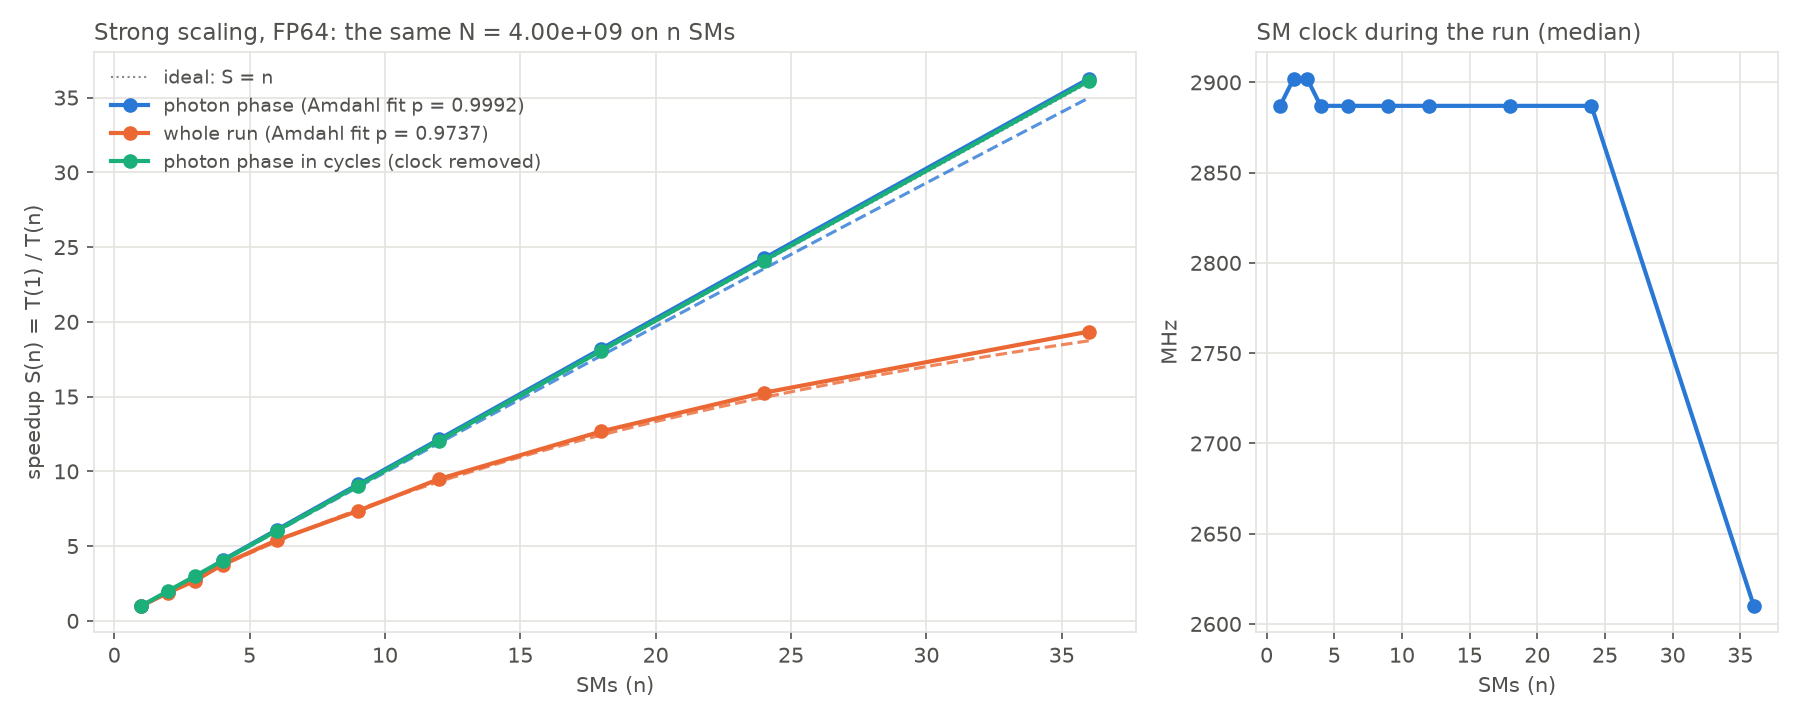

In [6]:
strong = load("scaling")["strong-fp64"]
table([{"sms": n, "photons": strong["photon_time"][str(n)], "whole": strong["whole_run_time"][str(n)],
         "s_photons": strong["speedup_photon_phase"][str(n)], "s_whole": strong["speedup_whole_run"][str(n)],
         "s_cycles": strong["speedup_cycles"].get(str(n)), "mhz": strong["sm_clock_mhz"].get(str(n))}
       for n in strong["sms"]],
      [("SMs", "sms", None), ("photon phase (s)", "photons", ".3f"), ("whole run (s)", "whole", ".3f"),
       ("speedup, photons", "s_photons", ".2f"), ("speedup, whole run", "s_whole", ".2f"),
       ("speedup, cycles", "s_cycles", ".2f"), ("SM clock (MHz)", "mhz", ".0f")])

figure("figures/strong_fp64.png")

| SMs | photon phase (s) | whole run (s) | speedup, photons | speedup, whole run | speedup, cycles | SM clock (MHz) |
|---|---|---|---|---|---|---|
| 1 | 158.917 | 164.447 | 1.00 | 1.00 | 1.00 | 2895 |
| 2 | 76.270 | 81.916 | 2.08 | 2.01 | 2.02 | 2895 |
| 3 | 50.857 | 56.534 | 3.12 | 2.91 | 3.03 | 2895 |
| 4 | 38.170 | 43.598 | 4.16 | 3.77 | 4.03 | 2895 |
| 6 | 25.474 | 31.184 | 6.24 | 5.27 | 6.05 | 2895 |
| 9 | 16.994 | 22.684 | 9.35 | 7.25 | 9.07 | 2887 |
| 12 | 12.760 | 18.185 | 12.45 | 9.04 | 12.09 | 2887 |
| 18 | 8.526 | 13.926 | 18.64 | 11.81 | 18.15 | 2880 |
| 24 | 6.412 | 11.462 | 24.78 | 14.35 | 24.19 | 2880 |
| 36 | 4.502 | 10.086 | 35.30 | 16.30 | 36.28 | 2017 |

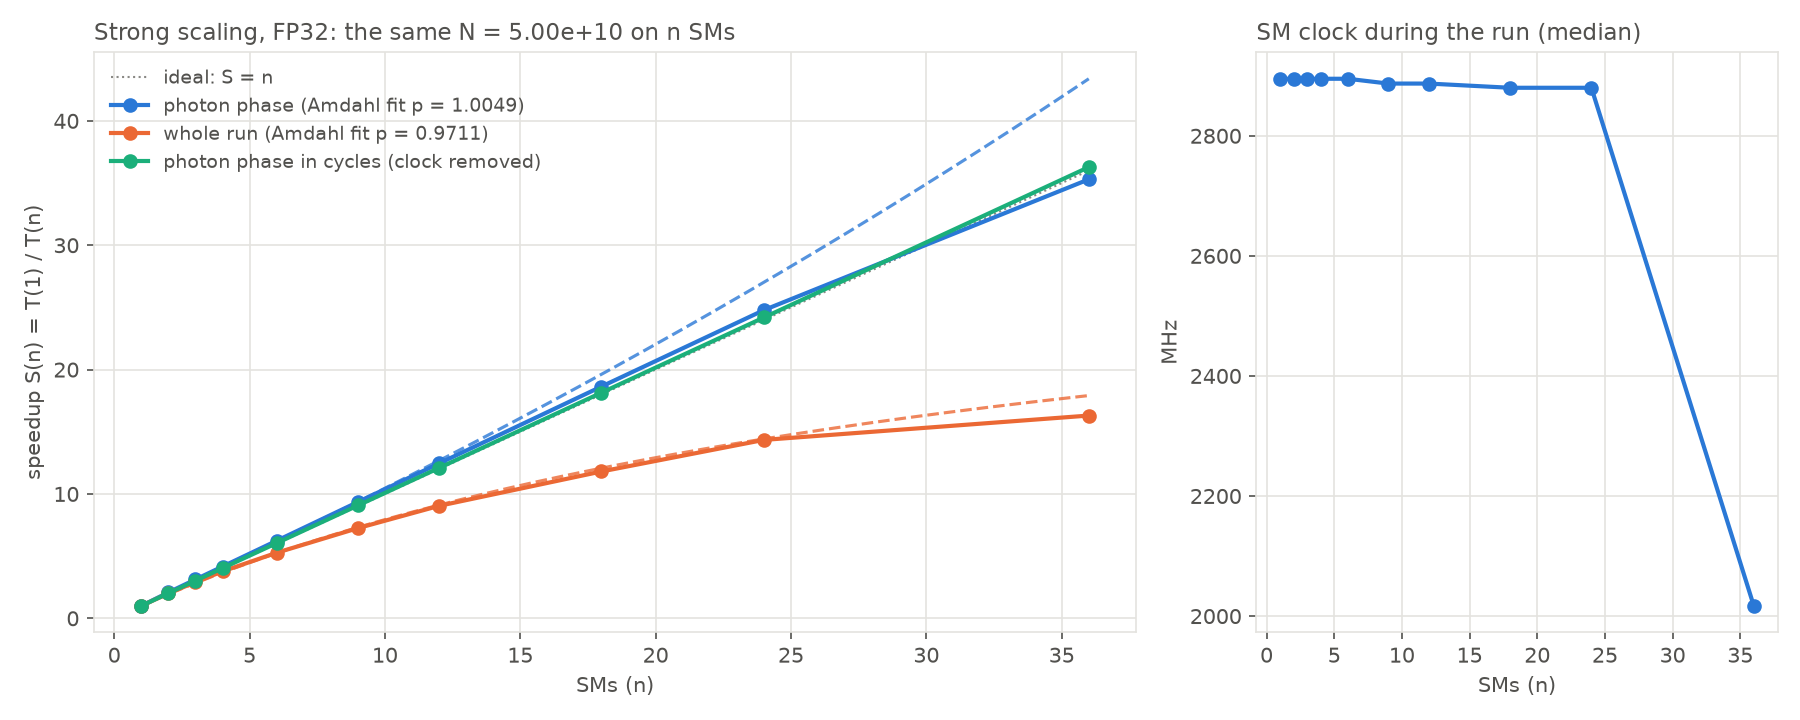

In [7]:
strong = load("scaling")["strong-fp32"]
table([{"sms": n, "photons": strong["photon_time"][str(n)], "whole": strong["whole_run_time"][str(n)],
         "s_photons": strong["speedup_photon_phase"][str(n)], "s_whole": strong["speedup_whole_run"][str(n)],
         "s_cycles": strong["speedup_cycles"].get(str(n)), "mhz": strong["sm_clock_mhz"].get(str(n))}
       for n in strong["sms"]],
      [("SMs", "sms", None), ("photon phase (s)", "photons", ".3f"), ("whole run (s)", "whole", ".3f"),
       ("speedup, photons", "s_photons", ".2f"), ("speedup, whole run", "s_whole", ".2f"),
       ("speedup, cycles", "s_cycles", ".2f"), ("SM clock (MHz)", "mhz", ".0f")])

figure("figures/strong_fp32.png")

**What it means.**
- FP64, N = 4.00e+09: 36.3× on 36 SMs for the photon phase (Amdahl p = 0.9992), 19.3× for the whole run (p = 0.9737, ceiling 1/s = 38); in cycles 36.1×, so the difference from the seconds is the clock. The serial share measured from the phases: 0.0259 (fitted: 0.0263).
- FP32, N = 5.00e+10: 35.3× on 36 SMs for the photon phase (Amdahl p = 1.0049), 16.3× for the whole run (p = 0.9711, ceiling 1/s = 35); in cycles 36.3×, so the difference from the seconds is the clock. The serial share measured from the phases: 0.0341 (fitted: 0.0289).

### 5.2 Weak scaling

FP64


| SMs | N | photon phase (s) | whole run (s) | scaled speedup | efficiency |
|---|---|---|---|---|---|
| 1 | 1.11e+08 | 5.942 | 11.059 | 1.00 | 1.000 |
| 2 | 2.22e+08 | 5.931 | 11.447 | 1.49 | 1.002 |
| 3 | 3.33e+08 | 5.932 | 11.502 | 1.99 | 1.002 |
| 4 | 4.44e+08 | 5.934 | 11.588 | 2.49 | 1.001 |
| 6 | 6.67e+08 | 5.935 | 11.667 | 3.49 | 1.001 |
| 9 | 1.00e+09 | 5.947 | 11.574 | 5.06 | 0.999 |
| 12 | 1.33e+09 | 5.952 | 11.776 | 6.49 | 0.998 |
| 18 | 2.00e+09 | 5.969 | 11.162 | 10.04 | 0.996 |
| 24 | 2.67e+09 | 5.970 | 11.328 | 13.04 | 0.995 |
| 36 | 4.00e+09 | 5.982 | 11.549 | 18.96 | 0.993 |

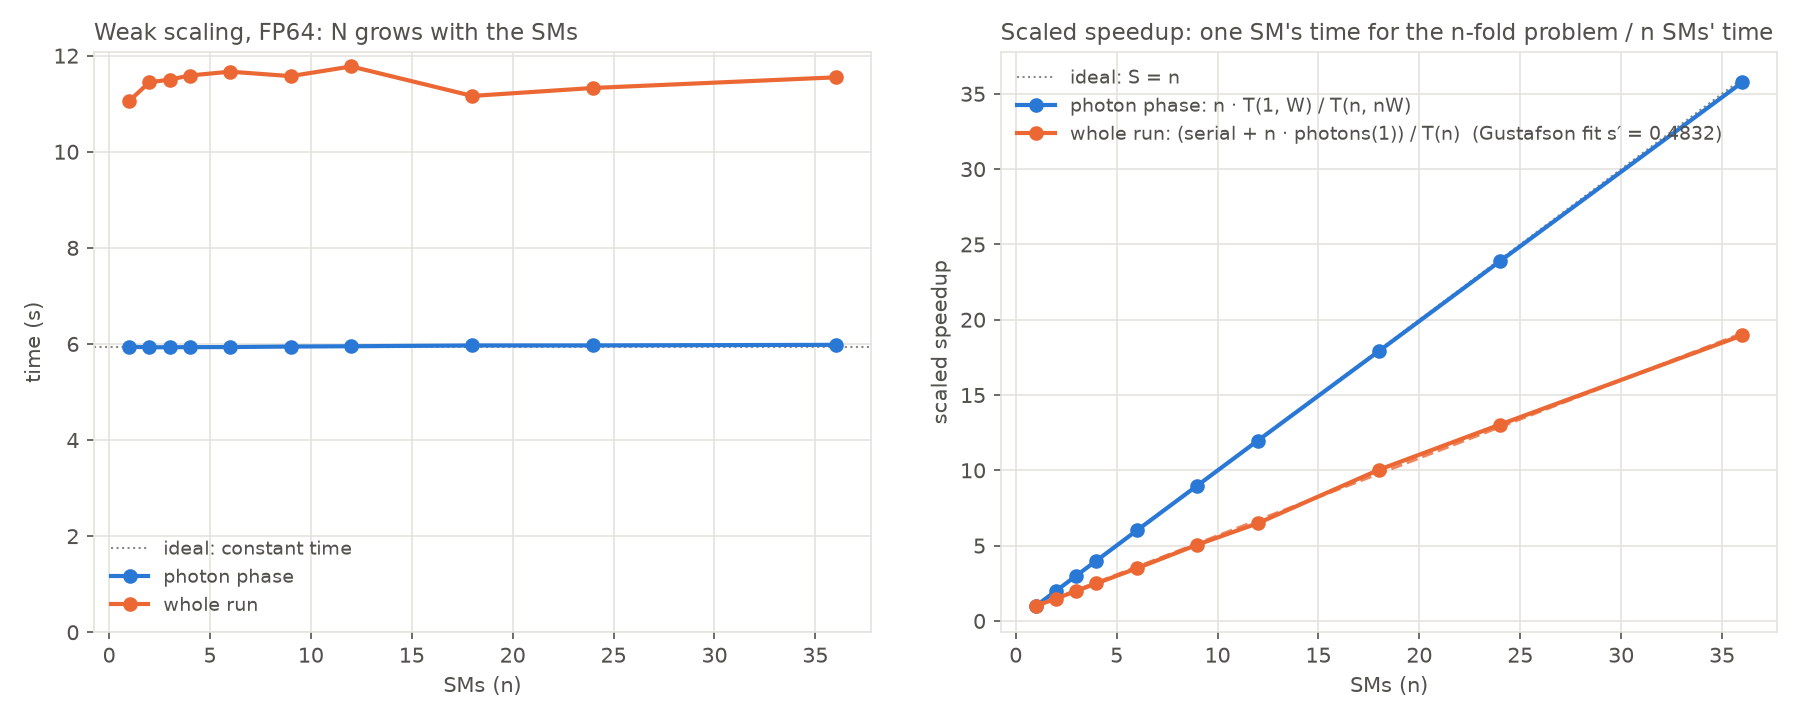

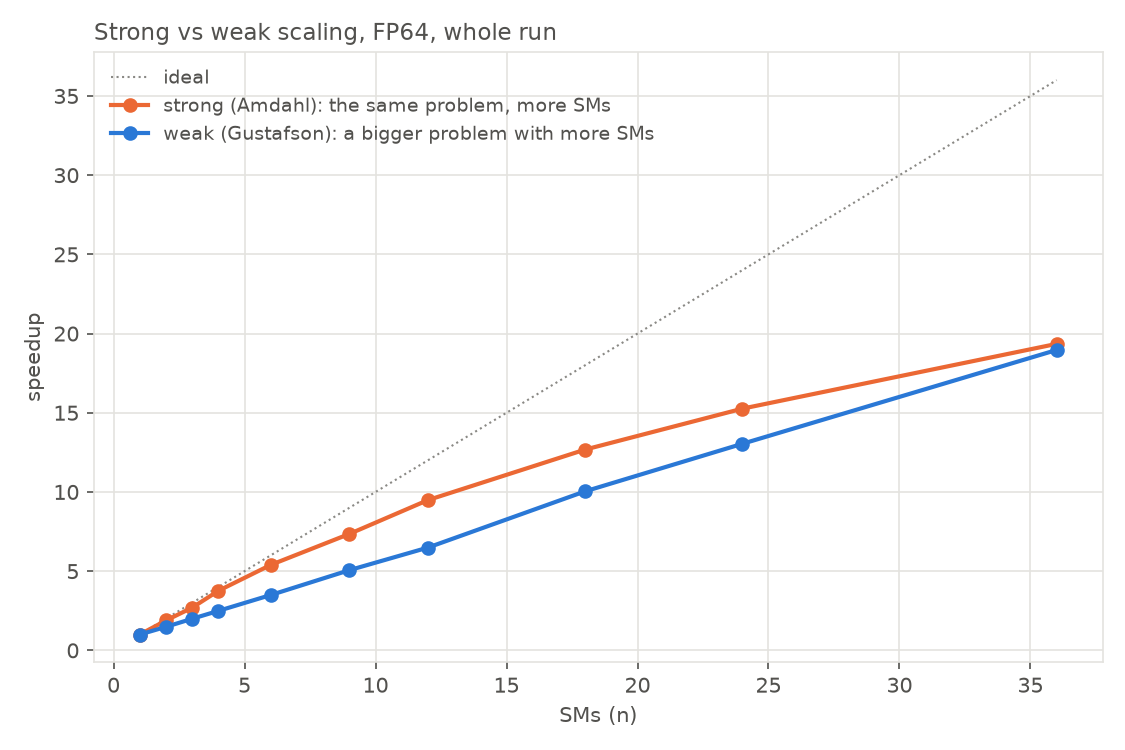

FP32


| SMs | N | photon phase (s) | whole run (s) | scaled speedup | efficiency |
|---|---|---|---|---|---|
| 1 | 1.39e+09 | 4.229 | 9.025 | 1.00 | 1.000 |
| 2 | 2.78e+09 | 4.248 | 9.043 | 1.47 | 0.996 |
| 3 | 4.17e+09 | 4.252 | 9.126 | 1.92 | 0.995 |
| 4 | 5.56e+09 | 4.254 | 9.203 | 2.36 | 0.994 |
| 6 | 8.33e+09 | 4.259 | 9.330 | 3.23 | 0.993 |
| 9 | 1.25e+10 | 4.260 | 9.009 | 4.76 | 0.993 |
| 12 | 1.67e+10 | 4.263 | 9.468 | 5.87 | 0.992 |
| 18 | 2.50e+10 | 4.271 | 9.214 | 8.78 | 0.990 |
| 24 | 3.33e+10 | 4.290 | 9.613 | 11.06 | 0.986 |
| 36 | 5.00e+10 | 4.502 | 10.086 | 15.57 | 0.939 |

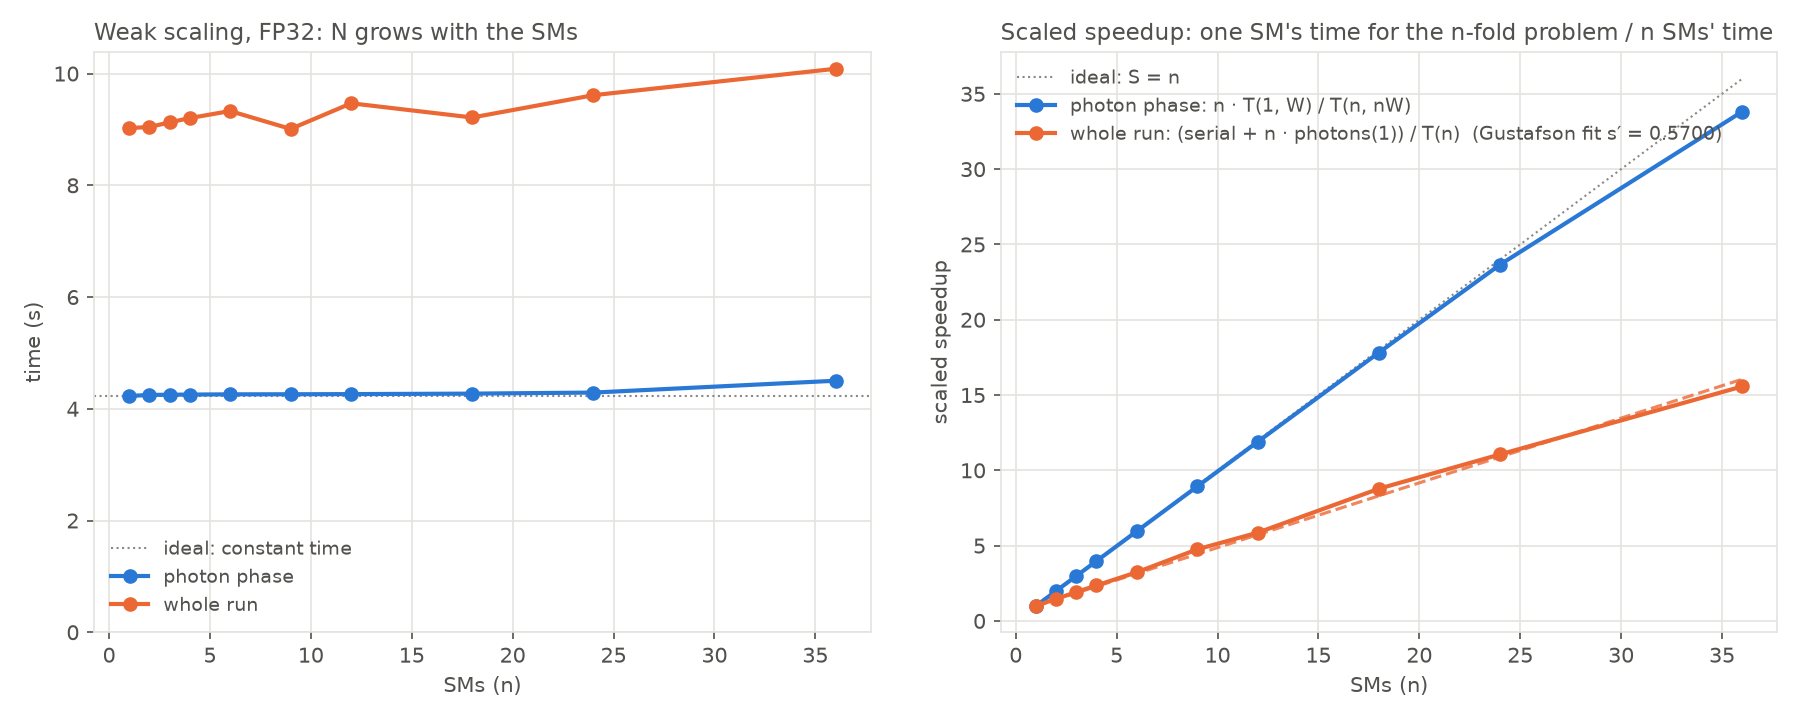

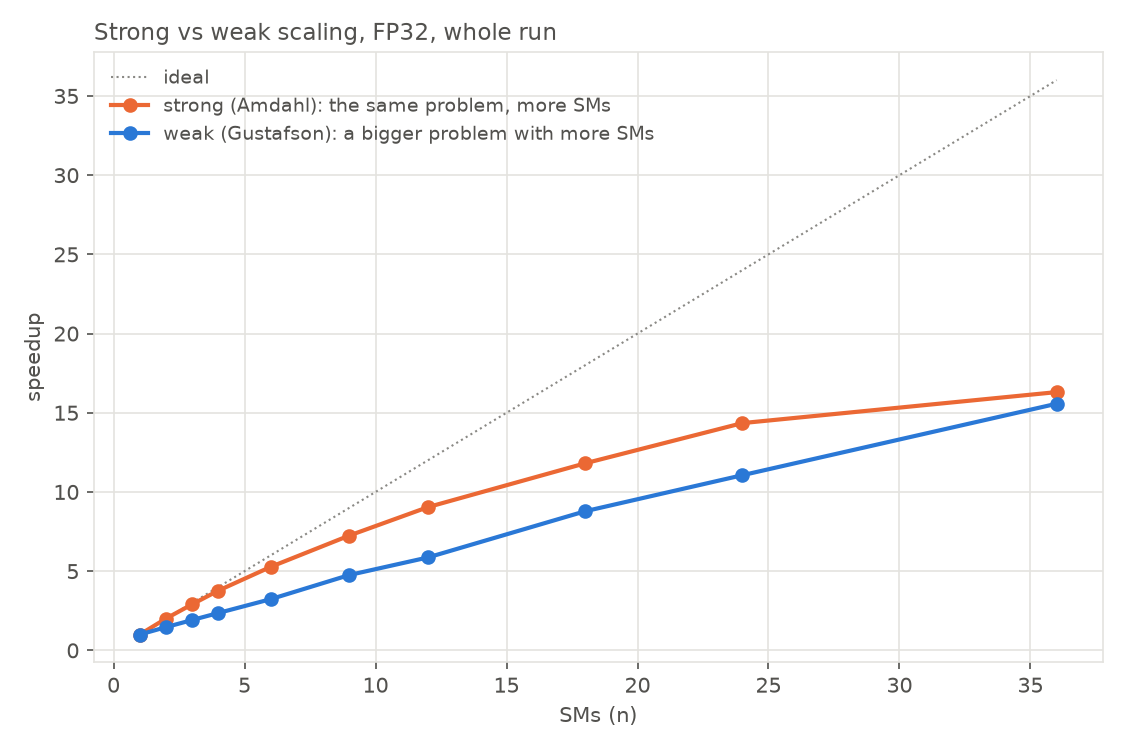

In [8]:
for precision in (64, 32):
    weak = load("scaling")[f"weak-fp{precision}"]
    print(f"FP{precision}")
    table([{"sms": n, "photons": weak["photons"][str(n)], "time": weak["photon_time"][str(n)],
            "whole": weak["whole_run_time"][str(n)], "scaled": weak["scaled_speedup_whole_run"][str(n)],
            "efficiency": weak["efficiency_photon_phase"][str(n)]} for n in weak["sms"]],
          [("SMs", "sms", None), ("N", "photons", ".2e"), ("photon phase (s)", "time", ".3f"),
           ("whole run (s)", "whole", ".3f"), ("scaled speedup", "scaled", ".2f"), ("efficiency", "efficiency", ".3f")])
    figure(f"figures/weak_fp{precision}.png")
    figure(f"figures/strong_vs_weak_fp{precision}.png")

**What it means.**
- FP64: on 36 SMs the efficiency is 0.993; Gustafson's serial share fitted s′ = 0.4832, measured 0.4789.
- FP32: on 36 SMs the efficiency is 0.939; Gustafson's serial share fitted s′ = 0.5700, measured 0.5536.

### 5.3 Amdahl's ceiling, at valid N: the image is the serial part

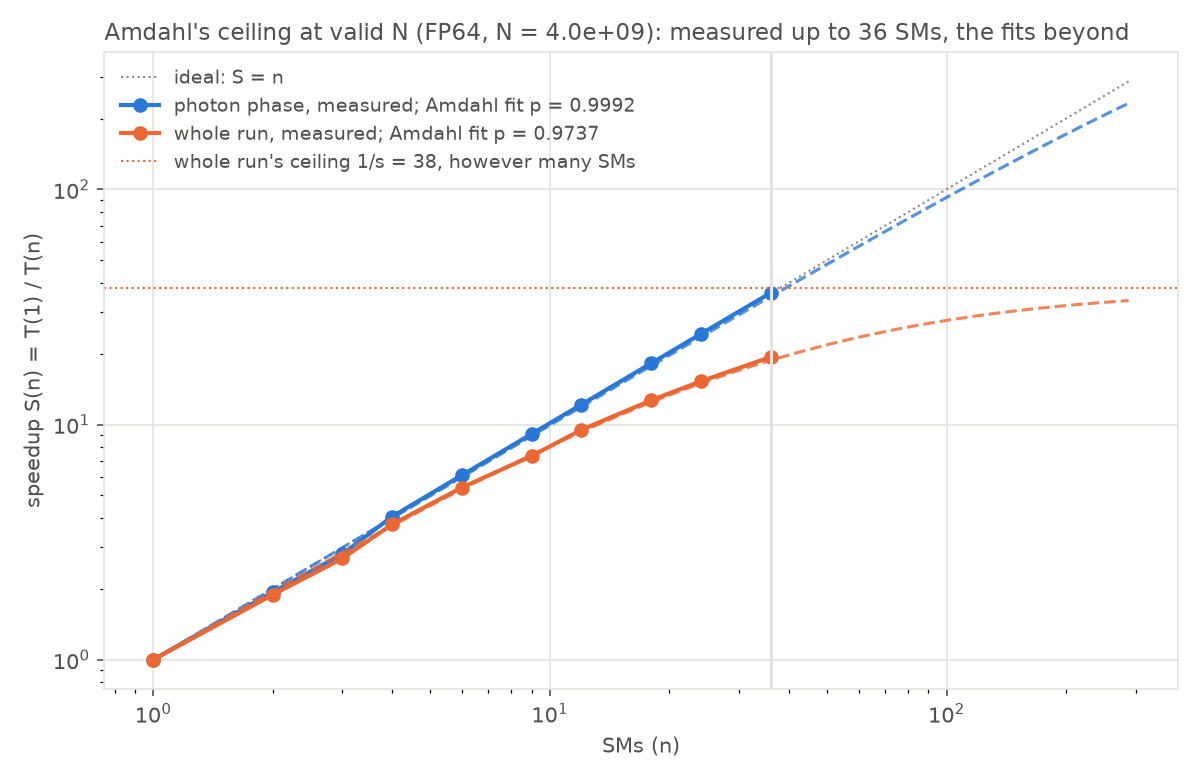

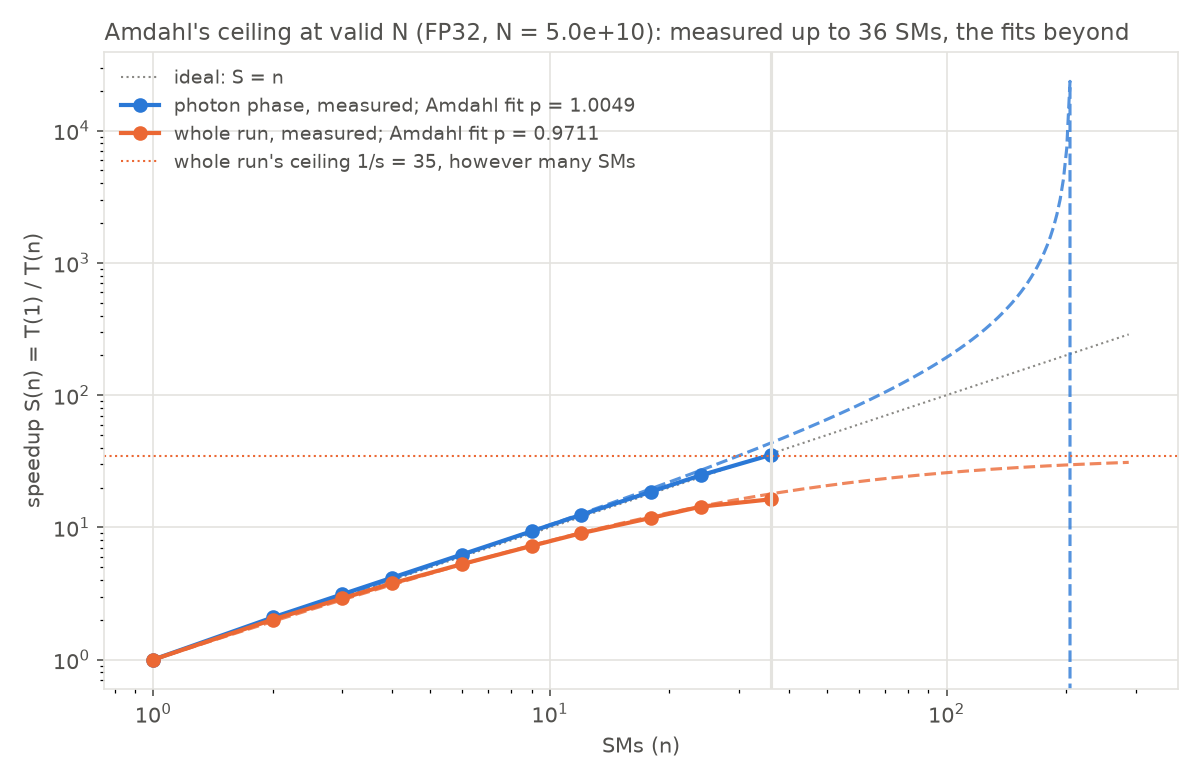

In [9]:
figure("figures/amdahl_ceiling_fp64.png")
figure("figures/amdahl_ceiling_fp32.png")

**What it means.**
- FP64: on 36 SMs a run is 6.0 s of photons and 5.6 s of everything else (setup, zeroing, copying back and saving the image), so the whole run is 19.3× faster than on one SM while the photons are 36.3×. Amdahl: s = 0.0263, so the whole run can never pass 1/s = 38×, however many SMs.
- FP32: on 36 SMs a run is 4.5 s of photons and 5.6 s of everything else (setup, zeroing, copying back and saving the image), so the whole run is 16.3× faster than on one SM while the photons are 35.3×. Amdahl: s = 0.0289, so the whole run can never pass 1/s = 35×, however many SMs.
- The photons are the parallel part; the image is the serial part: one disk saves it, one PCIe link copies it, and
  that time doesn't shrink with the SMs. The bigger the image, the lower the ceiling.

### 5.4 p(N): the parallel fraction grows with the problem (valid N only)

| N | p, photon phase | p, whole run |
|---|---|---|
| 2e+10 | 0.99817 | 0.92145 |
| 5e+10 | 0.99943 | 0.96549 |
| 1e+11 | 0.99823 | 0.98040 |

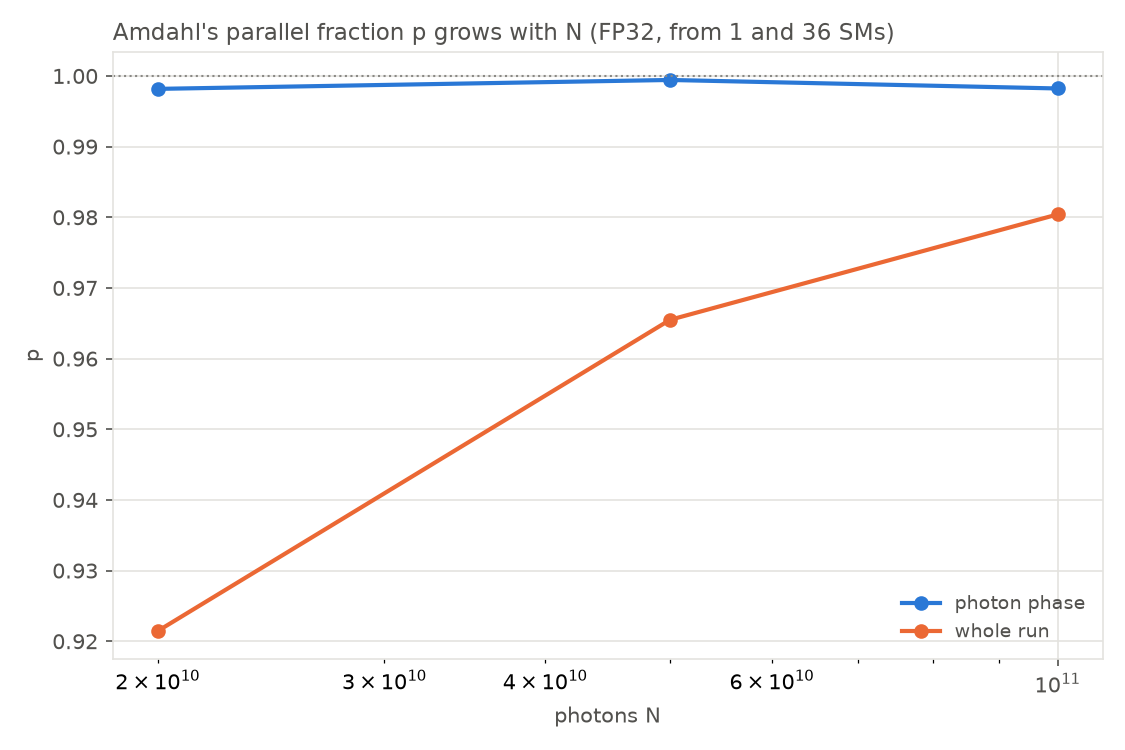

In [10]:
size = load("scaling")["problem-size-fp32"]
table([{"n": int(n), "p_photons": size["p_photon_phase"][str(n)], "p_whole": size["p_whole_run"][str(n)]}
       for n in size["sizes"]], [("N", "n", ".0e"), ("p, photon phase", "p_photons", ".5f"), ("p, whole run", "p_whole", ".5f")])
figure("figures/problem_size.png")

**What it means.** Amdahl's p is not a property of the program alone: from N = 2e+10 to
1e+11 it goes from 0.998 to 0.99823
for the photon phase, and from 0.921 to 0.9804 for the
whole run. The work grows with N; the serial part (the image) doesn't, so the more photons, the larger the share
that the SMs can share.

**Caveats.** On many SMs in FP32 the clock falls under the power cap, so seconds understate the scaling; the cycles
don't (the "speedup, cycles" column). Every run here is above the minimum N: none is too short to be a measurement.

## 6. Resolution and image size: what each one costs (costs)

**Question.** What does a sharper picture cost, and what does a bigger one cost? They are two different axes.

**Axis 1, resolution: the bins, and so the computation.** A photon leaves the star in one direction; the direction
picks its frame (one of `frames` bins of the rotation) and its μ bin (one of nμ bins of μ = cos i). A frame of one
observer collects every photon of its cell, each projected along its own direction, so it **blends the views inside
the cell**: a blur of about R·2π/frames pixels along the rotation, and R·Δi across it, where Δi ≈ (2/nμ)/sin i is the
cell's width in inclination (R = size/2 pixels). Bins equal in μ are equal in photons but not in angle: Δi is
smallest at the equator and largest at the poles (the polar bin spans 0 to ≈ 2/√nμ radians). With nμ = frames/π the
two blurs match at the equator. Finer bins share the photons among more cells, so the photons needed for an SNR are

N = SNR² · nμ · frames · (π/4)·size² · (1 + 2a/3), and the time is passes × N / (photons per second).

**Axis 2, image size: the bytes, and so the memory.** One observer's image is frames × size² counts of 4 bytes; a run
holds all its observers: observers × frames × size² × 4 bytes. When they don't fit in the GPU's memory, the run makes
**passes**, and each pass traces all N photons again: memory turns into time.

**Which knob is on which axis.** The **observers** are only on the memory axis: each one keeps the photons of its
own bin, whatever the others do, so more observers need no more photons, only more memory (and passes). The
**frames** are on both: they sharpen the rotation, cost photons, and multiply the bytes. The **size** is on both:
more pixels need more photons for the same SNR, and more bytes. nμ only costs photons.

**Method.** Not a run: the formulas above with this GPU's measured speed (1.11e+10 photons/s in FP32,
6.69e+08 in FP64; measured in this run) and its memory for the image
(7.07 GB), for SNR 10 at the limb. The SNR formula is checked by every
`make` (measured = predicted), and the passes by the engine's `--describe`.

| size | frames | nμ | observers | N for the SNR | time FP32 | time FP64 | GB | passes | blur: rotation (px) | blur: polar bin (px) | video (s at 30 fps) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 512² | 150 | 47 | 4 | 2.4e+11 | 0.4 min | 6.0 min | 0.63 | 1 | 10.7 | 75 | 5 |
| 512² | 150 | 47 | 7 | 2.4e+11 | 0.4 min | 6.0 min | 1.10 | 1 | 10.7 | 75 | 5 |
| 512² | 300 | 95 | 4 | 9.8e+11 | 1.5 min | 24.4 min | 1.26 | 1 | 5.4 | 53 | 10 |
| 512² | 300 | 95 | 7 | 9.8e+11 | 1.5 min | 24.4 min | 2.20 | 1 | 5.4 | 53 | 10 |
| 512² | 600 | 191 | 4 | 3.9e+12 | 5.9 min | 1.6 h | 2.52 | 1 | 2.7 | 37 | 20 |
| 512² | 600 | 191 | 7 | 3.9e+12 | 5.9 min | 1.6 h | 4.40 | 1 | 2.7 | 37 | 20 |
| 512² | 1000 | 319 | 4 | 1.1e+13 | 16.4 min | 4.5 h | 4.19 | 1 | 1.6 | 29 | 33 |
| 512² | 1000 | 319 | 7 | 1.1e+13 | 32.9 min | 9.1 h | 7.34 | 2 | 1.6 | 29 | 33 |
| 1024² | 150 | 47 | 4 | 9.7e+11 | 1.5 min | 24.1 min | 2.52 | 1 | 21.4 | 150 | 5 |
| 1024² | 150 | 47 | 7 | 9.7e+11 | 1.5 min | 24.1 min | 4.40 | 1 | 21.4 | 150 | 5 |
| 1024² | 300 | 95 | 4 | 3.9e+12 | 5.9 min | 1.6 h | 5.03 | 1 | 10.7 | 105 | 10 |
| 1024² | 300 | 95 | 7 | 3.9e+12 | 11.7 min | 3.3 h | 8.81 | 2 | 10.7 | 105 | 10 |
| 1024² | 600 | 191 | 4 | 1.6e+13 | 47.2 min | 13.1 h | 10.07 | 2 | 5.4 | 74 | 20 |
| 1024² | 600 | 191 | 7 | 1.6e+13 | 1.6 h | 26.1 h | 17.62 | 4 | 5.4 | 74 | 20 |
| 1024² | 1000 | 319 | 4 | 4.4e+13 | 4.4 h | 72.8 h | 16.78 | 4 | 3.2 | 57 | 33 |
| 1024² | 1000 | 319 | 7 | 4.4e+13 | 7.7 h | 127.3 h | 29.36 | 7 | 3.2 | 57 | 33 |
| 2048² | 150 | 47 | 4 | 3.9e+12 | 11.6 min | 3.2 h | 10.07 | 2 | 42.9 | 300 | 5 |
| 2048² | 150 | 47 | 7 | 3.9e+12 | 23.2 min | 6.4 h | 17.62 | 4 | 42.9 | 300 | 5 |
| 2048² | 300 | 95 | 4 | 1.6e+13 | 1.6 h | 26.0 h | 20.13 | 4 | 21.4 | 210 | 10 |
| 2048² | 300 | 95 | 7 | 1.6e+13 | 2.7 h | 45.5 h | 35.23 | 7 | 21.4 | 210 | 10 |
| 2048² | 600 | 191 | 4 | 6.3e+13 | — | — | 40.27 | — | 10.7 | 148 | 20 |
| 2048² | 600 | 191 | 7 | 6.3e+13 | — | — | 70.46 | — | 10.7 | 148 | 20 |
| 2048² | 1000 | 319 | 4 | 1.8e+14 | — | — | 67.11 | — | 6.4 | 115 | 33 |
| 2048² | 1000 | 319 | 7 | 1.8e+14 | — | — | 117.44 | — | 6.4 | 115 | 33 |

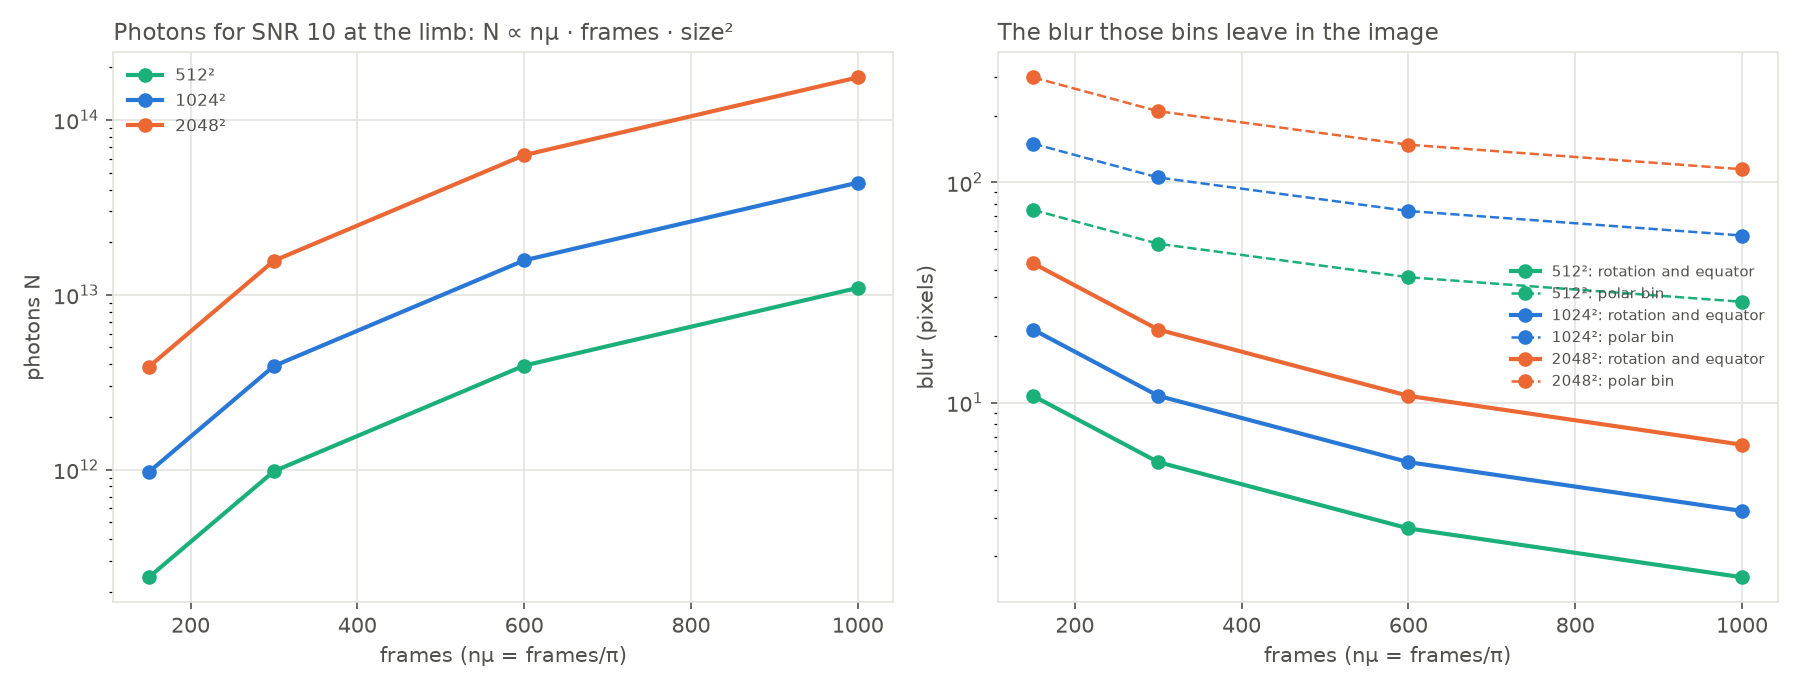

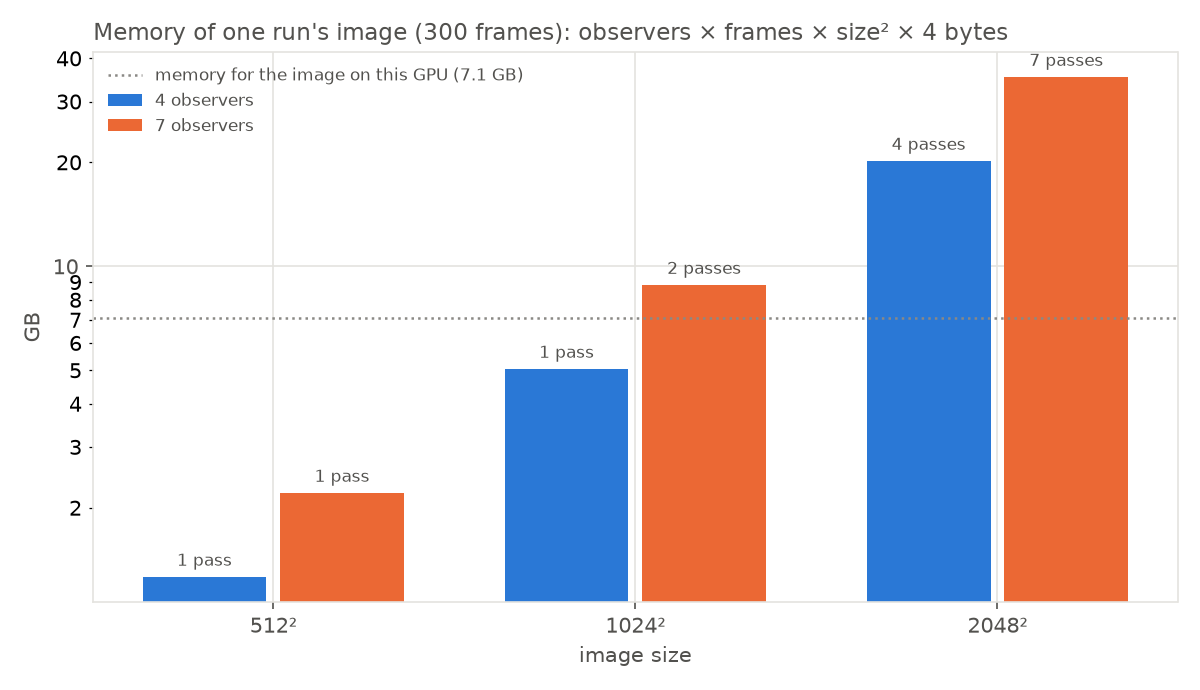

In [11]:
costs = load("costs")
def hours(seconds):
    return "—" if seconds is None else f"{seconds / 60:.1f} min" if seconds < 5400 else f"{seconds / 3600:.1f} h"
table(costs["rows"], [("size", lambda r: f"{r['size']}²", None), ("frames", "frames", None), ("nμ", "nmu", None),
                      ("observers", "observers", None), ("N for the SNR", "photons", ".1e"),
                      ("time FP32", lambda r: hours(r["seconds"]), None),
                      ("time FP64", lambda r: hours(r["seconds_fp64"]), None),
                      ("GB", lambda r: r["bytes"] / 1e9, ".2f"), ("passes", "passes", None),
                      ("blur: rotation (px)", "rotation_blur_px", ".1f"), ("blur: polar bin (px)", "pole_blur_px", ".0f"),
                      ("video (s at 30 fps)", "video_seconds_at_30fps", ".0f")])
figure("figures/costs_compute.png")
figure("figures/costs_memory.png")

**What it means.**
- The showcase: 1024², 300 frames (nμ 95), 4 observers: N = 3.9e+12, 6 min in FP32, 5.0 GB (1 pass); blur 11 px (rotation, equator), 105 px (polar bin).
- The same with 7 observers: 1024², 300 frames (nμ 95), 7 observers: N = 3.9e+12, 12 min in FP32, 8.8 GB (2 passes); blur 11 px (rotation, equator), 105 px (polar bin). More observers, the same N: only the memory grew, and with it the
  passes, which each trace all N again.
- Twice the size: 2048², 300 frames (nμ 95), 4 observers: N = 1.6e+13, 1.6 h in FP32, 20.1 GB (4 passes); blur 21 px (rotation, equator), 210 px (polar bin). Four times the pixels: 4× the photons and 4× the bytes, and the blur doubles in
  pixels (it is the same in angle).
- Twice the size **and** the same blur in pixels: 2048², 600 frames (nμ 191), 4 observers: N = 6.3e+13, — in FP32, 40.3 GB (does not fit); blur 11 px (rotation, equator), 148 px (polar bin). Twice the frames and twice nμ on top of
  4× the pixels: about 16× the photons of the 1k showcase. Sharpness at a fixed pixel scale grows as size⁴.
- A picture as sharp as its pixels (a blur of 1 px) would need frames ≈ π·size and nμ ≈ size: at 1k about 3200 frames
  and 1019 bins, ~10¹⁴–10¹⁵ photons: out of reach with this algorithm. The honest description of an image is its
  pixels **and** its blur.

### 6.1 How large an N for the best scaling, and what it costs to measure

**Question.** The whole run (photons + saving the image) scales less than the photons, because the image's serial part
is fixed. How large must N be for the whole run to come close to ideal, and how long would that take to measure?

**Method.** From this measurement: the speed on one SM and on all of them, and the serial part of a run
(5.6 s in FP32, 5.5 s in FP64: setup, copying back and saving the
image). Then T(n) = N / speed(n) + serial, for any N. A strong sweep needs the same N on every SM count, so its cost
is dominated by the run on one SM.

| precision | N | 1 SM | all SMs | whole-run speedup | strong sweep (1 repeat) | weak sweep (1 repeat) |
|---|---|---|---|---|---|---|
| FP64 | 4e+09 | 4 min | 12 s | 19.3 | 10 min | 2 min |
| FP64 | 1e+11 | 1.5 h | 3 min | 35.0 | 3.9 h | 26 min |
| FP64 | 1e+12 | 15.1 h | 25 min | 36.1 | 38.7 h | 4.2 h |
| FP64 | 1e+13 | 150.6 h | 4.2 h | 36.2 | 387.0 h | 41.6 h |
| FP32 | 5e+10 | 3 min | 10 s | 16.3 | 8 min | 2 min |
| FP32 | 1e+11 | 5 min | 15 s | 22.2 | 15 min | 2 min |
| FP32 | 1e+12 | 53 min | 2 min | 33.3 | 2.3 h | 16 min |
| FP32 | 1e+13 | 8.8 h | 15 min | 35.1 | 22.7 h | 2.5 h |

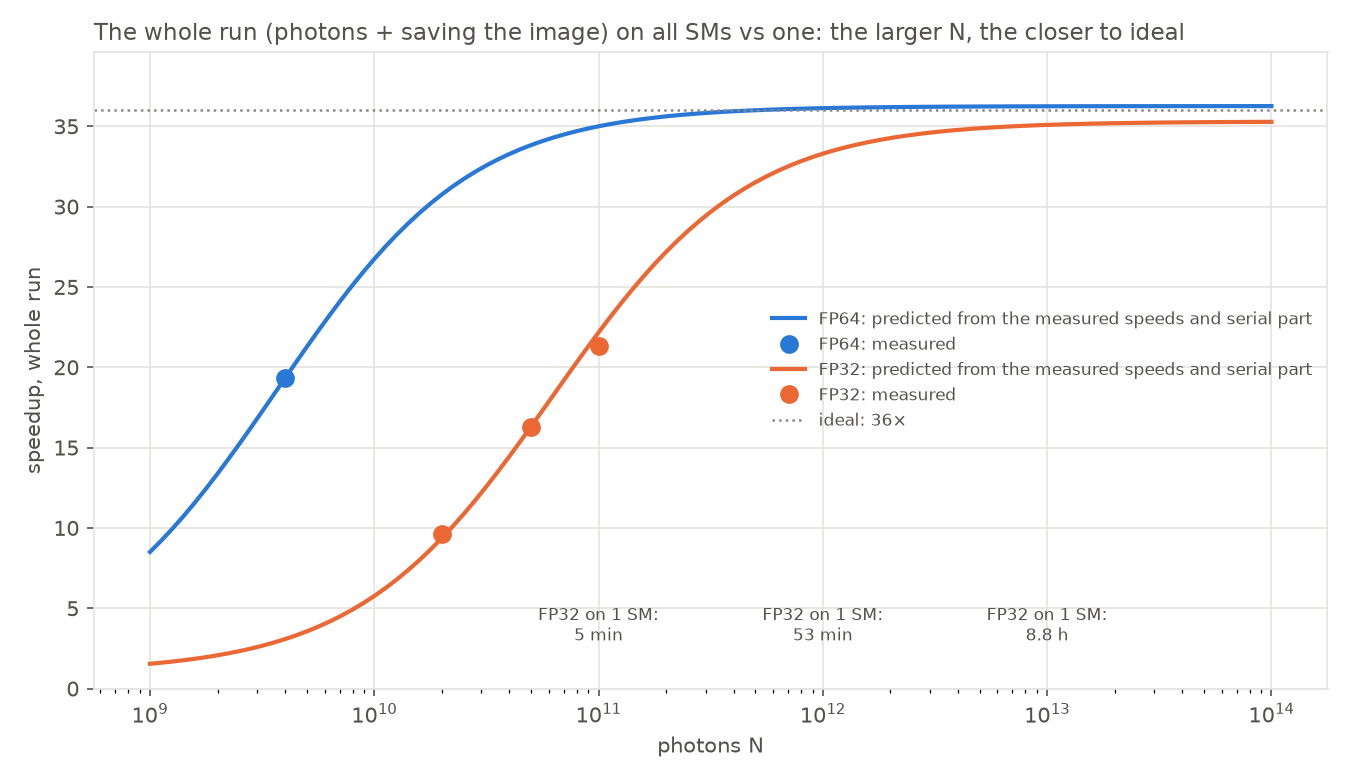

In [12]:
large = load("costs")["large_n"]
def hours(seconds):
    return f"{seconds:.0f} s" if seconds < 90 else f"{seconds / 60:.0f} min" if seconds < 5400 else f"{seconds / 3600:.1f} h"
table(large["rows"], [("precision", lambda r: f"FP{r['precision']}", None), ("N", "photons", ".0e"),
                      ("1 SM", lambda r: hours(r["one_sm_seconds"]), None),
                      ("all SMs", lambda r: hours(r["all_sms_seconds"]), None),
                      ("whole-run speedup", "whole_run_speedup", ".1f"),
                      ("strong sweep (1 repeat)", lambda r: hours(r["strong_sweep_seconds"]), None),
                      ("weak sweep (1 repeat)", lambda r: hours(r["weak_sweep_seconds"]), None)])
figure("figures/costs_large_n.png")

**What it means.**
- The measured points sit on the predicted curve: the whole run's speedup is the photons' speedup diluted by the fixed
  serial part, nothing else.
- FP32 at N = 10¹²: 33× on the whole run, and a strong sweep of
  2.3 h (one repeat). At 10¹³: 35.1×, but the run
  on one SM alone takes 8.8 h.
- FP64 gets there sooner, because each photon costs more: at 10¹¹ it is already 35×
  (3.9 h for the sweep).
- The cheap way to show near-ideal scaling at large N is the weak sweep: every point runs about as long as the run on
  all SMs.

**Caveats.** The times are predictions from the measured speed (`make` prints the same prediction and then measures
it). The polar bin is always the blurriest with equal-μ bins; observers away from the exact poles are sharper. An
algorithm that adds every photon to every observer and frame with its exact geometry ("peel-off") would remove the
blur and the 1/(nμ·frames) dilution, but it is not EP2's algorithm.

## Appendix: the data

**The folder.**
- `run.json`: what was asked (the options, the reference N per binary), the machine, the status.
- `machine.json`: the GPU's limits, the software, the environment checks, the minimum N.
- `plan.json`: every planned run with its prediction (seconds, memory, passes) and its validity.
- `points/<run>.json`: one file per engine run (the name says the binary, the variant, the SMs, N and the repeat).
- `parts/<part>.json`: the analyses, which these tables read:
- `parts/validation.json`
- `parts/speed.json`
- `parts/kernel.json`
- `parts/occupancy.json`
- `parts/scaling.json`
- `parts/costs.json`
- `figures/`: the figures, each with a `.json` of the numbers it plots.
- `progress.log`: each run's measured vs predicted time.

**The fields of a point.**

| field | meaning |
|---|---|
| `processor, precision, sms, photons, variant, repeat, star` | what was asked (sms empty = all SMs) |
| `SUMMARY.PHOTONS_TIME` | seconds of the photon phase (the kernel, or the CPU loop): the speed is measured on it |
| `SUMMARY.TIME` | seconds of the whole engine run: setup + zero + photons + copy + save |
| `SUMMARY.SETUP_TIME, ZERO_TIME, COPY_TIME, SAVE_TIME` | the serial parts of the run |
| `SUMMARY.PHOTONS_PER_SECOND` | N / PHOTONS_TIME |
| `SUMMARY.RECORDED, BLOCKED, MISSED` | photons that reached an observer's image, hit a spot, or no observer's μ bin |
| `SUMMARY.REGISTERS_PER_THREAD, LOCAL_BYTES_PER_THREAD` | the kernel's registers, and its local memory (spills) |
| `SUMMARY.THREADS_PER_BLOCK, BLOCKS_PER_UNIT, OCCUPANCY` | the launch chosen by the occupancy API |
| `KERNEL[].KERNEL_TIME` | seconds of each pass's kernel, from CUDA events |
| `SMS[].CYCLES` | clock cycles of the slowest SM in each pass: speed with the clock removed |
| `GPU_MONITOR.*` | nvidia-smi sampled every 200 ms: clock (MHz), power (W), temperature, and the share of samples with each clock-limit reason active (POWER_CAP, VOLTAGE_CEILING, ...) |
| `IMAGE_DIGEST` | a hash of the observers' images: equal digests = identical images, bit for bit |
| `PROCESS_TIME` | wall-clock seconds of the engine process, measured from Python |
| `validity` | valid (N at or above this GPU's minimum for that many SMs) or INVALID |